In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("dataset/diabetes_prediction_dataset.csv")

Data Analysis

In [5]:
# 1. Check the number of rows and columns
print("Dataset Shape:")
print(df.shape)

# 2. Check column names, data types, and missing values
print("\nDataset Information:")
df.info()

# 3. Check diabetes class balance
print("\nDiabetes Class Balance:")
print(df["diabetes"].value_counts(normalize=True).rename("proportion"))

# 4. Check the number of records in each diabetes class
print("\nDiabetes Counts:")
print(df["diabetes"].value_counts())

# 5. Get basic statistics for numerical columns
print("\nDescriptive Statistics:")
print(df.describe().T)

# 6. Check the categories in text columns
print("\nGender Distribution:")
print(df["gender"].value_counts())

print("\nSmoking History Distribution:")
print(df["smoking_history"].value_counts())

Dataset Shape:
(100000, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Diabetes Class Balance:
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

Diabetes Counts:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Descriptive Statistics:
                        count 

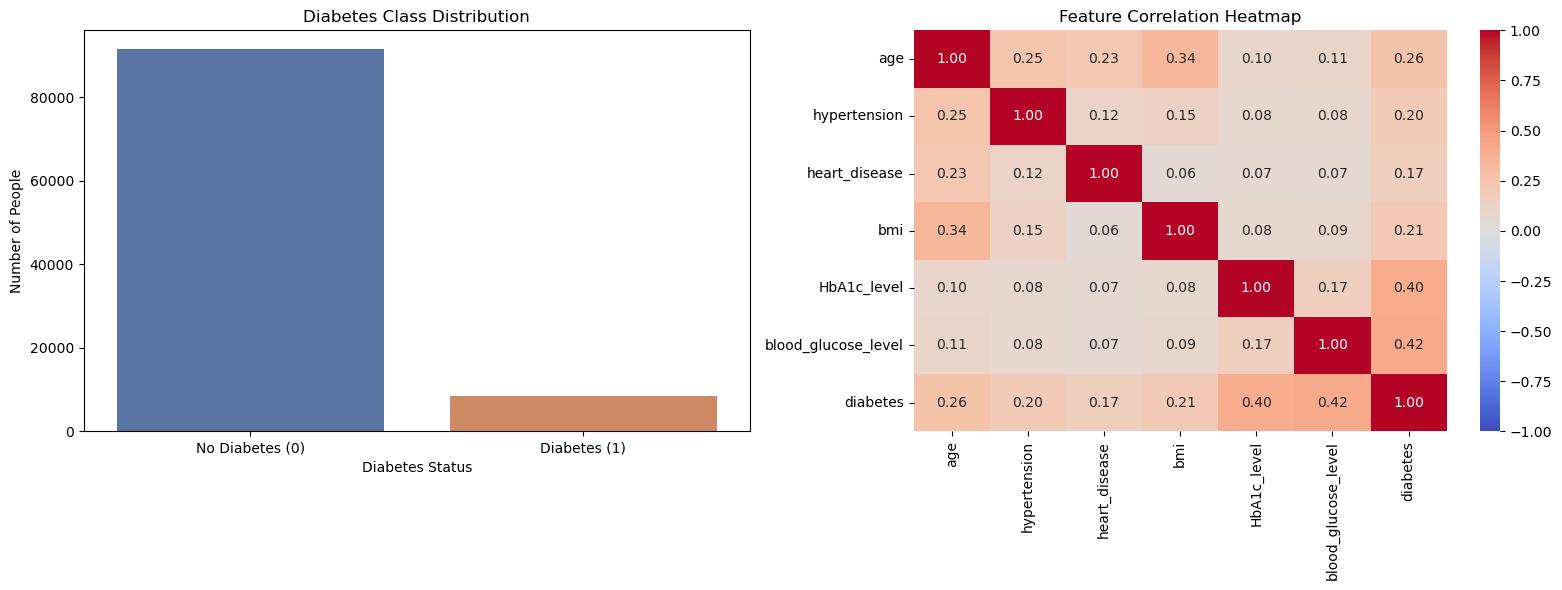

In [6]:
# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Diabetes class distribution
sns.countplot(
    data=df,
    x="diabetes",
    hue="diabetes",
    order=[0, 1],
    hue_order=[0, 1],
    palette={0: "#4C72B0", 1: "#DD8452"},
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Diabetes Class Distribution")
axes[0].set_xlabel("Diabetes Status")
axes[0].set_ylabel("Number of People")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Diabetes (0)", "Diabetes (1)"])

# 2. Feature correlation heatmap
numerical_df = df.select_dtypes(include="number")
correlation = numerical_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1]
)

axes[1].set_title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()


Training models

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


RANDOM_STATE = 42
# Separate features and target
X = pd.get_dummies(df.drop(columns=["diabetes"]), drop_first=True)
y = df["diabetes"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Print dataset sizes
print(f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}")

Train size: 80000 | Test size: 20000


define models


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

models = {
    "Decision Tree": {
        "model": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        "scaled": False
    },
    "Random Forest": {
        "model": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE),
        "scaled": False
    },
    "KNN": {
        "model": KNeighborsClassifier(n_neighbors=11),
        "scaled": True
    },
    "SVM (RBF)": {
        "model": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE),
        "scaled": True
    },
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "scaled": True
    }
}

Train and Evaluate


In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

results = []
conf_matrices = {}

for name, spec in models.items():
    model = spec["model"]

    if spec["scaled"]:
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    conf_matrices[name] = cm

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    })

    print(f"--- {name} ---")
    print(classification_report(
        y_test, y_pred,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    ))

--- Decision Tree ---
              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.99     18300
    Diabetes       1.00      0.67      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.99      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000

--- Random Forest ---
              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.99     18300
    Diabetes       1.00      0.67      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.99      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000

--- KNN ---
              precision    recall  f1-score   support

 No Diabetes       0.96      1.00      0.98     18300
    Diabetes       0.92      0.59      0.72      1700

    accuracy                           0.96     20000
   macro avg       0.94      0.79      0.85     20000
weighted avg      

KeyboardInterrupt: 

In [ ]:
results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df.style.background_gradient(cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1-score"])


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.972300,1.000000,0.674118,0.805341
1,Random Forest,0.972300,1.000000,0.674118,0.805341
2,SVM (RBF),0.963600,0.965517,0.592941,0.734694
3,Logistic Regression,0.960500,0.859400,0.640000,0.733648
4,KNN,0.960850,0.923361,0.588235,0.718649


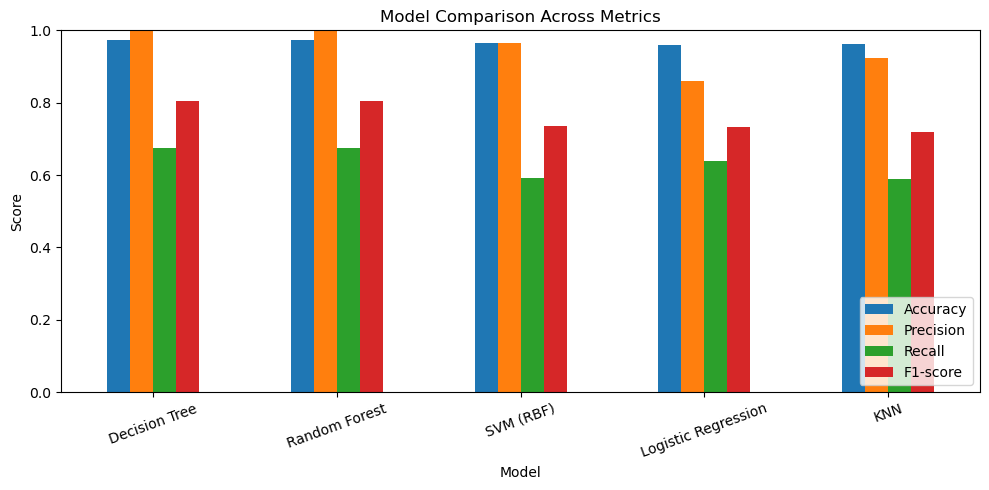

In [ ]:
results_df.plot(
    x="Model", y=["Accuracy", "Precision", "Recall", "F1-score"],
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
plt.title("Model Comparison Across Metrics")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


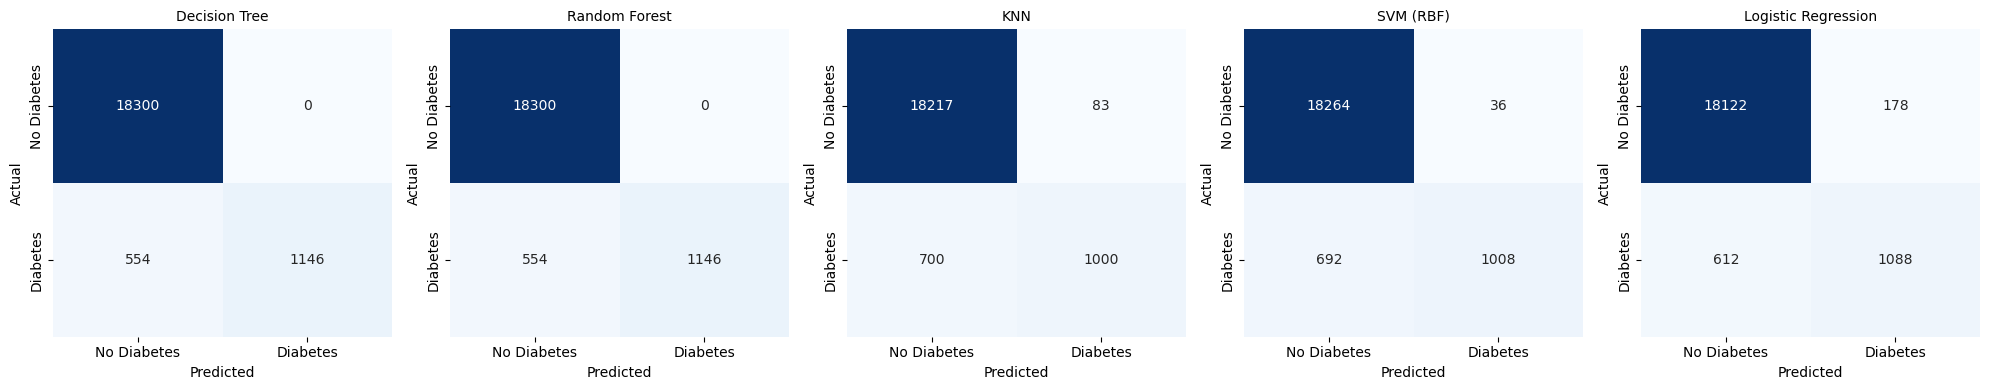

In [ ]:
#Confusion matrices
fig, axes = plt.subplots(
    1, len(conf_matrices),
    figsize=(4 * len(conf_matrices), 4)
)

for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"]
    )

    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
best_row = results_df.iloc[0]

print(f"Best-performing model by F1-score: {best_row['Model']}")
print(results_df.to_string(index=False))

print("""
How to read this:
- Accuracy shows the overall percentage of correct predictions.
- Recall is important because it measures how many actual diabetes cases the model identifies.
- Precision measures how many predicted diabetes cases are actually diabetic.
- F1-score balances precision and recall and is used to rank the models.
- The best model is selected based on F1-score, but recall should also be considered
  when predicting diabetes.
""")

Best-performing model by F1-score: Decision Tree
              Model  Accuracy  Precision   Recall  F1-score
      Decision Tree   0.97230   1.000000 0.674118  0.805341
      Random Forest   0.97230   1.000000 0.674118  0.805341
          SVM (RBF)   0.96360   0.965517 0.592941  0.734694
Logistic Regression   0.96050   0.859400 0.640000  0.733648
                KNN   0.96085   0.923361 0.588235  0.718649

How to read this:
- Accuracy shows the overall percentage of correct predictions.
- Recall is important because it measures how many actual diabetes cases the model identifies.
- Precision measures how many predicted diabetes cases are actually diabetic.
- F1-score balances precision and recall and is used to rank the models.
- The best model is selected based on F1-score, but recall should also be considered
  when predicting diabetes.



## Week 7: Cross-validation and tuning

Everything above is the week 6 version (one train/test split, default-ish hyperparameters). Below I redo it with cross-validation, a bit of feature engineering and GridSearchCV.

In [ ]:
from sklearn.dummy import DummyClassifier

# a "model" that always says no diabetes
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_dummy = dummy.predict(X_test)

print("Dummy accuracy:", accuracy_score(y_test, y_dummy))
print("Dummy recall:  ", recall_score(y_test, y_dummy))

Cross-validation (5-fold, stratified) on the same models. Scaling is inside a pipeline now so each fold only scales using its own training part.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1"]

cv_rows = []
for name, spec in models.items():
    m = clone(spec["model"])
    if name.startswith("SVM"):
        m.set_params(probability=False)   # much faster, not needed for cv
    if spec["scaled"]:
        m = make_pipeline(StandardScaler(), m)

    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    cv_rows.append({
        "Model": name,
        "CV Accuracy": s["test_accuracy"].mean(),
        "CV Precision": s["test_precision"].mean(),
        "CV Recall": s["test_recall"].mean(),
        "CV F1": s["test_f1"].mean(),
        "CV F1 std": s["test_f1"].std()
    })

cv_df = pd.DataFrame(cv_rows)
cv_df

In [ ]:
# single split f1 vs cross-validated f1
compare_cv = results_df[["Model", "F1-score"]].rename(columns={"F1-score": "Single split F1"}).merge(
    cv_df[["Model", "CV F1", "CV F1 std"]], on="Model"
)
compare_cv["Difference"] = compare_cv["CV F1"] - compare_cv["Single split F1"]
compare_cv.sort_values("CV F1", ascending=False).reset_index(drop=True)

Feature engineering. Categorical columns are already one-hot encoded and the scaling is in the pipeline, so the main thing left is outliers (bmi).

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["bmi", "HbA1c_level", "blood_glucose_level"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
# cap bmi at the 1st and 99th percentile of the training set
low, high = X_train["bmi"].quantile([0.01, 0.99])

X_train_fe = X_train.copy()
X_test_fe = X_test.copy()
X_train_fe["bmi"] = X_train_fe["bmi"].clip(low, high)
X_test_fe["bmi"] = X_test_fe["bmi"].clip(low, high)

print(f"bmi capped between {low:.1f} and {high:.1f}")

Hyperparameter tuning with GridSearchCV on the Random Forest. Using F1 as the score since accuracy is misleading here.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [6, 8, 12],
    "min_samples_leaf": [1, 5],
    "class_weight": [None, "balanced"]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)
grid.fit(X_train_fe, y_train)

print("Best params:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 4))

In [ ]:
# top 5 combinations
cv_results = pd.DataFrame(grid.cv_results_)
cv_results[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(5)

Before vs after (same test set)

In [ ]:
best_rf = grid.best_estimator_
y_pred_tuned = best_rf.predict(X_test_fe)

rf_before = results_df[results_df["Model"] == "Random Forest"].iloc[0]

before_after = pd.DataFrame({
    "Before (week 6)": [rf_before["Accuracy"], rf_before["Precision"], rf_before["Recall"], rf_before["F1-score"]],
    "After (CV + tuned)": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
before_after["Change"] = before_after["After (CV + tuned)"] - before_after["Before (week 6)"]

before_after

In [ ]:
before_after[["Before (week 6)", "After (CV + tuned)"]].plot(kind="bar", figsize=(8, 5), ylim=(0, 1))
plt.title("Random Forest: before vs after tuning")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, cm) in zip(axes, [("Before", conf_matrices["Random Forest"]),
                                  ("After", confusion_matrix(y_test, y_pred_tuned))]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
    ax.set_title(f"Random Forest ({title})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()